In [26]:
#import libraries
from langgraph.graph import StateGraph,START, END
from typing import TypedDict

In [27]:
#define and initializing states in a dictionary
class Temperature(TypedDict):
    temp_c:float
    temp_f:float
    weather_label:str

Code for First Node

In [28]:
def convert_temp(state:Temperature)->Temperature:
    celsius=state['temp_c'] #since it is a dictionary we can access this way
    fahrenheit=(celsius*9/5)+32

    #update in the state
    state['temp_f']=round(fahrenheit,2)

    return state

Code for 2nd Node

In [29]:
def label_temperature(state:Temperature)->Temperature:
    fahrenheit=state['temp_f']

    if fahrenheit>=86:
        state['weather_label']='Hot'
    elif fahrenheit>=68:
        state['weather_label']='Warm'
    else:
        state['weather_label']='Cold'
    
    return state


In [ ]:
#define graph
graph=StateGraph(Temperature)   #ab data sab nodes ko mil jaegi

#add nodes to the graph
graph.add_node('convert_temp',convert_temp)

#adding one more node
graph.add_node('label_weather',label_temperature)


#add edges to the graph
graph.add_edge(START,'convert_temp')   #start---convert_temp

#adding anohter edge   after converting temperature it will go to label weather
graph.add_edge('convert_temp','label_weather')

#add edge
graph.add_edge('label_weather',END)

#compile the graph
workflow=graph.compile()



In [31]:
#execute the graph
initial_state=int(input("enter temperature in celsius"))
final_state=workflow.invoke({
    "temp_c":initial_state    #our input needs to be a dictionary
    })
print("output of graph is ", final_state)

output of graph is  {'temp_c': 45, 'temp_f': 113.0, 'weather_label': 'Hot'}


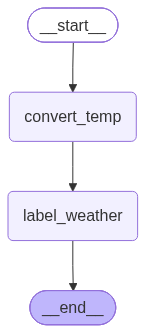

In [32]:
#visualizing graph
from IPython.display import Image, display

display(Image(workflow.get_graph().draw_mermaid_png()))

LLM WORKFLOW

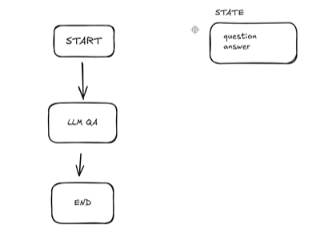